<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/Analitica_de_Datos/U3/Practica_1/AD_U3_Practica1_LlanasMia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Curso: Analitica de Datos

UNIDAD 3

Mia Llanas Hernández

No. 22111513


Este dataSet contiene 130 canciones de Twenty One Pilots basados en sus albums.
Contiene 130 filas y 26 columnas

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
top_df = pd.read_csv('/content/drive/MyDrive/DataSetTOP/twentyscience.csv')
top_df

,Unnamed: 0,album_release_date,album_release_year,danceability,energy,key,loudness,mode,speechiness,acousticness,...,duration_ms,explicit,is_local,track_name,track_number,type,album_name,key_name,mode_name,key_mode
0,1,2021-05-21,2021,0.684,0.677,7,-7.355,1,0.0401,0.110000,...,204400,False,False,Good Day,1,track,Scaled And Icy,G,major,G major
1,2,2021-05-21,2021,0.700,0.664,7,-8.211,1,0.0394,0.306000,...,223065,False,False,Choker,2,track,Scaled And Icy,G,major,G major
2,3,2021-05-21,2021,0.588,0.856,9,-5.242,0,0.0316,0.000818,...,175044,False,False,Shy Away,3,track,Scaled And Icy,A,minor,A minor
3,4,2021-05-21,2021,0.785,0.623,11,-6.923,1,0.0403,0.050500,...,216758,False,False,The Outside,4,track,Scaled And Icy,B,major,B major
4,5,2021-05-21,2021,0.687,0.890,8,-5.990,1,0.0344,0.003960,...,172232,False,False,Saturday,5,track,Scaled And Icy,G#,major,G# major
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,126,2009-12-29,2009,0.550,0.625,1,-8.213,0,0.0399,0.149000,...,277013,False,False,Trapdoor,10,track,Twenty One Pilots,C#,minor,C# minor
126,127,2009-12-29,2009,0.618,0.732,5,-4.609,1,0.0724,0.147000,...,273786,False,False,"A Car, A Torch, A Death",11,track,Twenty One Pilots,F,major,F major
127,128,2009-12-29,2009,0.567,0.572,9,-7.694,1,0.0318,0.166000,...,285733,False,False,Taxi Cab,12,track,Twenty One Pilots,A,major,A major
128,129,2009-12-29,2009,0.363,0.135,7,-11.166,0,0.0295,0.976000,...,233000,False,False,Before You Start Your Day,13,track,Twenty One Pilots,G,minor,G minor


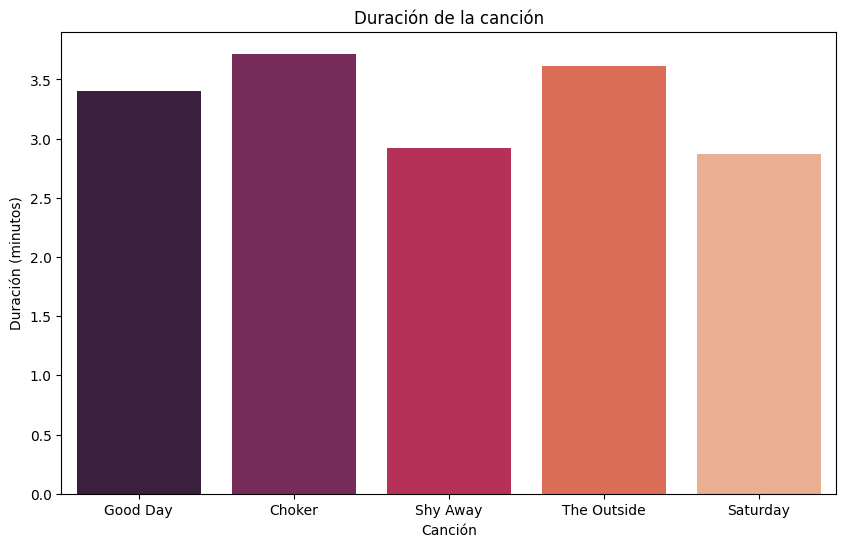

In [3]:
plt.figure(figsize=(10,6)) # Tamaño de la gráfica
# Convertimos duration_ms a minutos creando una columna temporal para el gráfico
temp_df = top_df.head(5).copy()
temp_df['duration_min'] = temp_df['duration_ms'] / 60000

sns.barplot(data=temp_df, x='track_name', y='duration_min', palette='rocket', hue='track_name', legend=False)
plt.title('Duración de la canción')
plt.ylabel('Duración (minutos)')
plt.xlabel('Canción')
plt.show()

In [4]:
# Calcular el promedio de 'danceability' y 'energy' agrupado por álbum
promedio_album = top_df.groupby('album_name')[['danceability', 'energy']].mean().reset_index()
display(promedio_album)

,album_name,danceability,energy
0,Blurryface,0.642643,0.726214
1,Scaled And Icy,0.683727,0.674818
2,Spotify Sessions,0.640143,0.399143
3,Trench,0.667214,0.618571
4,Twenty One Pilots,0.567857,0.539571
5,Vessel,0.668556,0.540024
6,Vessel (with Bonus Tracks),0.671188,0.631819


El deseability es para medir que tan dapta la canción para bailar y la energía es para medir que tan elevado esta el ritmo del album


*   Sí es menor que 0.5 es que no estan apta de bailar y si es mayor que 0.6 es porque si es apta para bailar
*   Sí es menor que 0.5 en energia es porque el album no es muy energetico y si es mayor que 0.6 es porque el album no es tan energetico.





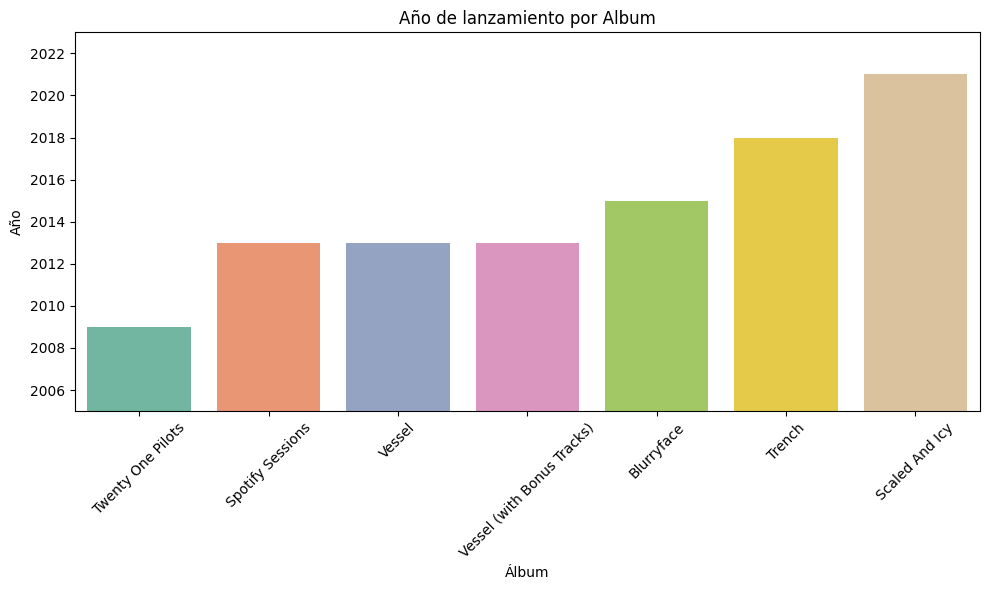

In [5]:
# Obtener los álbumes únicos con su año de lanzamiento
albunes_años = top_df.groupby('album_name')['album_release_year'].first().reset_index()
albunes_años = albunes_años.sort_values(by='album_release_year')

plt.figure(figsize=(10, 6))
sns.barplot(
    data=albunes_años,
    x='album_name',
    y='album_release_year',
    palette='Set2',
    hue='album_name',
    legend=False
)

# Ajustar el límite del eje Y para apreciar mejor la diferencia de años
plt.ylim(2005, 2023)

plt.title('Año de lanzamiento por Album')
plt.ylabel('Año')
plt.xlabel('Álbum')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Beneficio vs Ingresos')

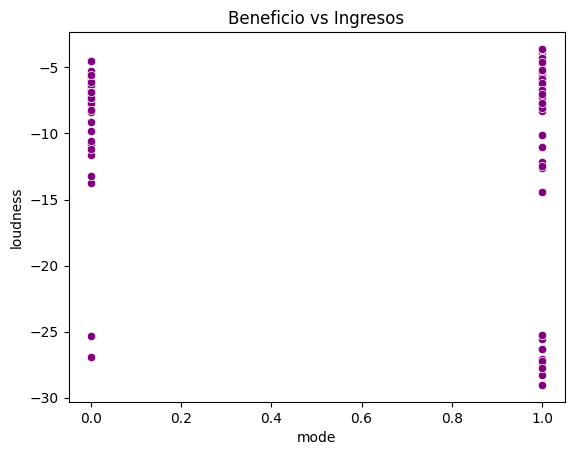

In [6]:
sns.scatterplot(data=top_df, x='mode', y='loudness', color='purple')
plt.title('Beneficio vs Ingresos')

eleccionamos las columnas numéricas de audio como características de entrada y elegimos mode_name comp lo que queremos predecir.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Seleccionar características de audio (X) y la variable objetivo (y)
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

X = top_df[features]
y = top_df['mode_name'] # Puede ser 'major' o 'minor'

Dividimos el dataset para entrenar el modelo con el 80% de las canciones y probar su eficacia con el 20% restante.

In [9]:
# 2. División train/test (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Inicializamos el clasificador y lo entrenamos con los datos correspondientes.

In [10]:
# 3. Inicializar y entrenar el modelo
tree_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

Generamos predicciones sobre el conjunto de prueba y medimos qué tan bien se comporta el modelo mediante la exactitud (accuracy) y una matriz de confusión.

In [11]:
# 4. Predicciones y evaluación
y_pred = tree_model.predict(X_test)

print("Exactitud (Accuracy):", accuracy_score(y_test, y_pred))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred))

Exactitud (Accuracy): 0.7307692307692307

Matriz de confusión:
 [[13  2]
 [ 5  6]]

Reporte de clasificación:
               precision    recall  f1-score   support

       major       0.72      0.87      0.79        15
       minor       0.75      0.55      0.63        11

    accuracy                           0.73        26
   macro avg       0.74      0.71      0.71        26
weighted avg       0.73      0.73      0.72        26



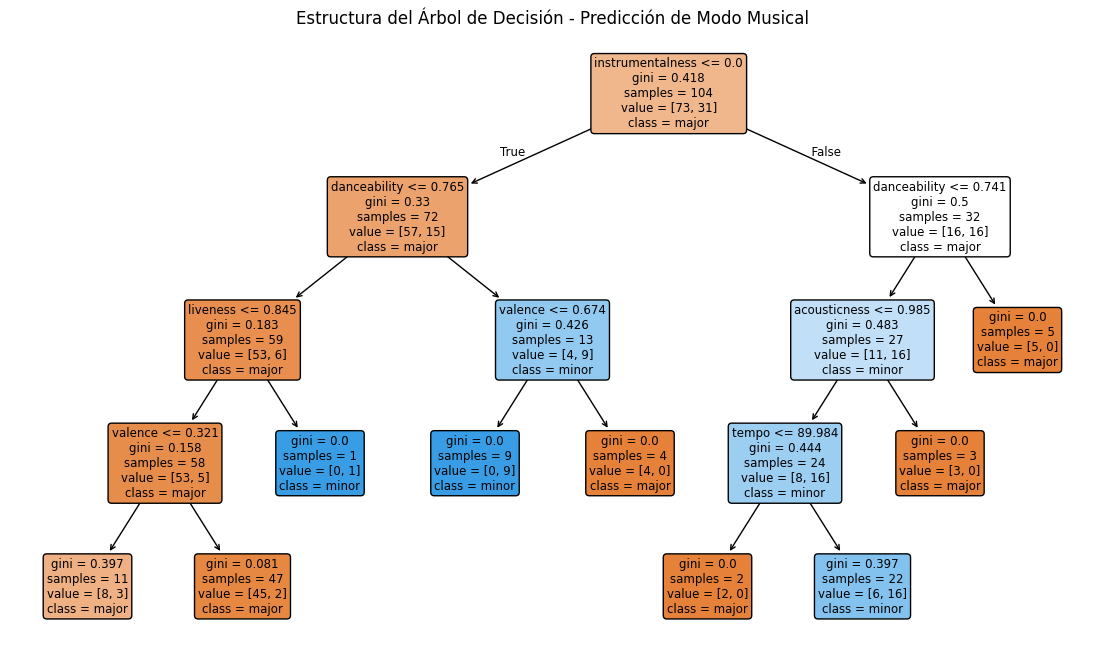

In [12]:
# 5. Graficar la estructura del árbol
plt.figure(figsize=(14, 8))
plot_tree(tree_model,
          feature_names=features,
          class_names=tree_model.classes_,
          filled=True,
          rounded=True)
plt.title("Estructura del Árbol de Decisión - Predicción de Modo Musical")
plt.show()